In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
# Run FIRST, before any transformers/tf imports
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
os.environ["TRANSFORMERS_NO_TORCHVISION"] = "1"
print("Env set: CPU-only, no-TF, protobuf=python")


Env set: CPU-only, no-TF, protobuf=python


# Environment, Paths, and Upload (if needed)

Creates Data/ and Outputs_Task2/, resolves the cleaned CSV, and if it’s missing:

Colab/Jupyter: shows an upload widget; saves to Data/… and sets CSV_CLEAN.

Kaggle: asks you to attach the dataset with Add data.

In [2]:
# ===== Cell 1: Env, Paths, and Upload-if-missing =====
import os
from pathlib import Path
import datetime
import pandas as pd

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TRANSFORMERS_NO_TORCHVISION"] = "1"

def is_kaggle(): return Path("/kaggle/working").exists()
def is_colab():
    try:
        import google.colab  # type: ignore
        return True
    except Exception:
        return False

ENV  = "kaggle" if is_kaggle() else ("colab" if is_colab() else "local")
ROOT = Path("/kaggle/working") if ENV == "kaggle" else (Path("/content") if ENV == "colab" else Path("."))

DATA_DIR = ROOT / "Data"; DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR  = ROOT / "Task2_Outputs"; OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_LOCAL = Path("../Data/melbourne_cafes_restaurants_clean.csv")  # repo copy of the clean dataset
KAGGLE_CSV = Path("/kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv")
CANDIDATES = [
    CSV_LOCAL,
    KAGGLE_CSV,
    DATA_DIR / "melbourne_cafes_restaurants_clean.csv",
    ROOT / "melbourne_cafes_restaurants_clean.csv",
]
CSV_CLEAN = next((p for p in CANDIDATES if p.exists()), None)

print(f"ENV: {ENV}")
print(f"ROOT: {ROOT}")
print(f"Data dir: {DATA_DIR}")
print(f"Outputs dir: {OUT_DIR}")
print("Resolved CSV:", CSV_CLEAN if CSV_CLEAN else "NOT FOUND")

if CSV_CLEAN is None:
    if ENV == "kaggle":
        print("⚠️ Dataset not found. In Kaggle, use **Add input** (right sidebar) to attach "
              "'melbourne_cafes_restaurants_clean.csv' and re-run this cell.")
    else:
        try:
            from ipywidgets import FileUpload
            from IPython.display import display
            import io
            print("Please upload 'melbourne_cafes_restaurants_clean.csv' now...")
            upload = FileUpload(accept='.csv', multiple=False)
            display(upload)
            def _on_upload(change):
                if upload.value:
                    name = list(upload.value.keys())[0]
                    content = upload.value[name]['content']
                    target = DATA_DIR / "melbourne_cafes_restaurants_clean.csv"
                    with open(target, "wb") as f: f.write(content)
                    globals()["CSV_CLEAN"] = target.resolve()
                    print(f"Saved to: {target}")
            upload.observe(_on_upload, names='value')
        except Exception:
            try:
                from google.colab import files  # type: ignore
                print("Opening file picker…")
                up = files.upload()
                for name in up.keys():
                    target = DATA_DIR / "melbourne_cafes_restaurants_clean.csv"
                    with open(target, "wb") as f: f.write(up[name])
                    globals()["CSV_CLEAN"] = target.resolve()
                    print(f"Saved to: {target}")
            except Exception:
                print("Upload widget unavailable. Place the file in:", DATA_DIR)

RUN_TS = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")


ENV: kaggle
ROOT: /kaggle/working
Data dir: /kaggle/working/Data
Outputs dir: /kaggle/working/Task2_Outputs
Resolved CSV: /kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv


In [3]:
df = pd.read_csv(CSV_CLEAN)
print(df.shape)
df.head(3)

# Build a simple text field for classification
def make_text(r):
    bits = []
    if isinstance(r.get("name"), str): bits.append(r["name"])
    if isinstance(r.get("cuisine_primary"), str) and r["cuisine_primary"]:
        bits.append(f"cuisine={r['cuisine_primary']}")
    if isinstance(r.get("address_full"), str) and r["address_full"]:
        bits.append(r["address_full"])
    return " | ".join(bits) if bits else "venue"

if "text" not in df.columns:
    df["text"] = df.apply(make_text, axis=1)

# Keep a manageable sample for fast CPU demo (you can raise to 500–1000 later)
SAMPLE_N = 250
sample = df.sample(SAMPLE_N, random_state=42).reset_index(drop=True)
sample[["name","cuisine_primary","amenity","text"]].head(5)

(1896, 31)


,name,cuisine_primary,amenity,text
0,Criniti's,italian,restaurant,Criniti's — italian
1,Schmucks Bagels,NaN,cafe,Schmucks Bagels
2,Grill Room,NaN,restaurant,Grill Room — Melbourne
3,Tipo 00,italian,restaurant,Tipo 00 — italian
4,Brunos,NaN,cafe,Brunos


# Behind the pipeline

Goal: show the internal steps that happen when you run a Transformers pipeline.

Explanation:
This cell manually breaks down what happens in the background:

The text and candidate labels are paired as premise + hypothesis.

The tokenizer converts them into numerical tensors (input_ids, attention_mask).

The model (facebook/bart-large-mnli) produces logits for the MNLI classes (contradiction, neutral, entailment).

After softmax, the entailment probability was kept per label.
It demonstrates the technical pipeline workflow required for BSBDAT501 2.1 – 2.3 and BSBCRT404 2.

Behind the pipeline — interpretation The pipeline (facebook/bart-large-mnli) creates a hypothesis for each label (“This place is a {label}.”), tokenizes the pair (premise, hypothesis), and the MNLI head outputs logits for contradiction/neutral/entailment. After softmax, we read the entailment probability per label. Here, “coffee shop” (0.995) and “cafe” (0.971) dominate, matching the input text. Others are ~0, so they’re unlikely.

In [4]:
# --- Tiny demo: "Behind the pipeline" on 1 example (FAST) ---
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""          # stay on CPU
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TRANSFORMERS_NO_TORCHVISION"] = "1"  # avoid torchvision import path

from transformers import pipeline
import torch

MODEL_NAME = "facebook/bart-large-mnli"
LABELS = ["cafe", "coffee shop", "restaurant", "bar", "dessert shop"]

zsp = pipeline("zero-shot-classification", model=MODEL_NAME, device=-1)

text = "Proud Mary is a specialty coffee shop in Collingwood."
tok = zsp.tokenizer(text, return_tensors="pt", truncation=True)

print("Tokenizer keys:", list(tok.keys()))
with torch.no_grad():
    out = zsp.model(**tok)  # MNLI logits: [batch, 3] (contradiction/neutral/entailment)
print("Raw logits shape:", out.logits.shape)

pred = zsp(text, candidate_labels=LABELS, multi_label=True)
pred  # shows labels + scores


E0000 00:00:1763214483.425593     235 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763214483.434801     235 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Device set to use cpu
Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.58.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


Tokenizer keys: ['input_ids', 'attention_mask']
Raw logits shape: torch.Size([1, 3])


{'sequence': 'Proud Mary is a specialty coffee shop in Collingwood.',
 'labels': ['coffee shop', 'cafe', 'bar', 'restaurant', 'dessert shop'],
 'scores': [0.9991660714149475,
  0.9973375797271729,
  0.0024478512350469828,
  0.0018220172496512532,
  8.183529280358925e-05]}

# Full pipeline demonstration

The next cell uses the Hugging Face pipeline() abstraction to replicate the zero-shot process automatically.
The model (facebook/bart-large-mnli) predicted coffee shop and cafe with the highest confidence, confirming the text describes a café-type venue.
This cell validates that the internal process (tokenization → model → softmax) produces interpretable results when wrapped in a ready-to-use pipeline.


Goal: run the official Hugging Face pipeline() API and confirm the automatic classification result.

What it shows:

The model and tokenizer are loaded together.

The text “Proud Mary is a specialty coffee shop in Collingwood.” is passed directly to the pipeline.

The output dictionary shows:

"labels" → candidate tags generated or passed in.

"scores" → entailment probabilities (softmaxed).

The top scores (coffee shop ≈ 0.995, cafe ≈ 0.971) confirm the model understood context correctly.

In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).eval()

CANDIDATE_LABELS = ["cafe","coffee shop","restaurant","bar","dessert shop"]
HYP = "This place is a {}."
premise = "Proud Mary is a specialty coffee shop in Collingwood."

# Find entailment index robustly
id2label = {int(k): v.upper() for k, v in mdl.config.id2label.items()}
ENTAIL_IDX = {v: k for k, v in id2label.items()}.get("ENTAILMENT", 2)

def classify_one(text, labels=CANDIDATE_LABELS, hyp=HYP):
    hyps = [hyp.format(l) for l in labels]
    batch = tok([text]*len(labels), hyps, return_tensors="pt", padding=True, truncation=True)
    with torch.no_grad():
        probs = torch.softmax(mdl(**batch).logits, dim=-1)[:, ENTAIL_IDX]
    # sort like pipeline
    pairs = sorted(zip(labels, probs.tolist()), key=lambda x: x[1], reverse=True)
    return {"sequence": text, "labels": [p[0] for p in pairs], "scores": [p[1] for p in pairs]}

manual_pred = classify_one(premise)
manual_pred


{'sequence': 'Proud Mary is a specialty coffee shop in Collingwood.',
 'labels': ['coffee shop', 'cafe', 'bar', 'restaurant', 'dessert shop'],
 'scores': [0.9948922395706177,
  0.9707340598106384,
  0.00025641763932071626,
  0.00024053905508480966,
  9.225223038811237e-05]}

In [8]:
from pathlib import Path

OUT_DIR = Path("./Task2_Outputs") if Path("./Task2_Outputs").exists() else Path("/kaggle/working/Task2_Outputs")
OUT_CSV = OUT_DIR / "zero_shot_per_venue_scores.csv"

if OUT_CSV.exists():
    OUT_CSV.unlink()
    print("Deleted old zero_shot_per_venue_scores.csv; next run will start from scratch.")
else:
    print("No existing zero_shot_per_venue_scores.csv found.")


Deleted old zero_shot_per_venue_scores.csv; next run will start from scratch.


In [19]:
# ===== Inference (fresh run, capped to 500 rows) =====
import time
import pandas as pd
from pathlib import Path
from transformers import pipeline

# 0) Ensure OUT_DIR and CSV_CLEAN exist (from Cell 1)
if 'OUT_DIR' not in globals():
    ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
    OUT_DIR = ROOT / "Task2_Outputs"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

assert 'CSV_CLEAN' in globals() and CSV_CLEAN is not None, "CSV_CLEAN is not set. Run Cell 1 first so CSV_CLEAN is resolved."

print(f"Using OUT_DIR: {OUT_DIR}")
print(f"Using CSV_CLEAN: {CSV_CLEAN}")

# 1) Load base dataframe
df_base = pd.read_csv(CSV_CLEAN)
TEXT_COL = "text" if "text" in df_base.columns else "name"
assert TEXT_COL in df_base.columns, f"Need a '{TEXT_COL}' column in the dataset."

df_work = df_base.copy()
df_work[TEXT_COL] = df_work[TEXT_COL].fillna("").astype(str).str.strip()
df_work = df_work.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

texts = df_work[TEXT_COL].tolist()
MAX_ROWS = 500   # <-- change to 100/200 if you want faster runs

if len(texts) > MAX_ROWS:
    texts = texts[:MAX_ROWS]
print(f"Total texts to classify in this run: {len(texts)}")

# 2) Initialise zero-shot pipeline (smaller model is okay for Task 2)
MODEL_NAME = "facebook/bart-large-mnli"
LABELS = ['coffee shop','cafe','bar','restaurant','dessert shop']

clf = pipeline(
    "zero-shot-classification",
    model=MODEL_NAME,
    device=-1   # CPU
)
print(f"Loaded zero-shot model: {MODEL_NAME}")

OUT_CSV = OUT_DIR / "zero_shot_per_venue_scores.csv"

# 3) If file exists, delete it so this run is fully fresh
if OUT_CSV.exists():
    OUT_CSV.unlink()
    print(f"Deleted existing file: {OUT_CSV}")

records = []
BATCH_SIZE = 8
t0 = time.time()

def run_batch(batch_texts):
    print(f"  → Calling pipeline on batch of size {len(batch_texts)}...")
    out = clf(batch_texts, LABELS, multi_label=True)
    print("    Pipeline call finished.")
    if isinstance(out, dict):
        out = [out]
    for o, s in zip(out, batch_texts):
        row = {"sequence": s}
        for lab, score in zip(o["labels"], o["scores"]):
            row[f"prob_{lab.replace(' ', '_')}"] = float(score)
        row["pred_label"] = o["labels"][0]
        row["pred_conf"]  = float(o["scores"][0])
        records.append(row)

n_total = len(texts)
processed = 0

print("Starting zero-shot inference...")
for bi in range(0, n_total, BATCH_SIZE):
    batch = texts[bi:bi+BATCH_SIZE]
    t_batch = time.time()
    run_batch(batch)
    processed += len(batch)
    batch_time = time.time() - t_batch
    elapsed = time.time() - t0

    print(f"Batch {bi//BATCH_SIZE + 1}: +{len(batch)} | "
          f"processed {processed}/{n_total} | "
          f"last batch {batch_time:.1f}s | elapsed {elapsed:.1f}s")

# 4) Save results
df_out = pd.DataFrame.from_records(records)
df_out.to_csv(OUT_CSV, index=False)

elapsed = time.time() - t0
print(f"\nDone. Saved: {OUT_CSV}")
print(f"Rows written: {len(df_out)}")
print(f"Total run time: {elapsed:.1f} seconds")
df_out.head(5)


Using OUT_DIR: /kaggle/working/Task2_Outputs
Using CSV_CLEAN: /kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv
Total texts to classify in this run: 500


Device set to use cpu


Loaded zero-shot model: facebook/bart-large-mnli
Starting zero-shot inference...
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 1: +8 | processed 8/500 | last batch 12.1s | elapsed 12.1s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 2: +8 | processed 16/500 | last batch 11.1s | elapsed 23.2s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 3: +8 | processed 24/500 | last batch 10.6s | elapsed 33.9s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 4: +8 | processed 32/500 | last batch 11.6s | elapsed 45.4s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 5: +8 | processed 40/500 | last batch 10.8s | elapsed 56.3s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 6: +8 | processed 48/500 | last batch 11.8s | elapsed 68.1s
  → Calling pipeline on batch of size 8...
    Pipeline call finished.
Batch 7: +8 | processed 56/

,sequence,prob_restaurant,prob_cafe,prob_bar,prob_coffee_shop,prob_dessert_shop,pred_label,pred_conf
0,Books n Bites Cafe — sandwich,0.997761,0.996941,0.004974,0.001164,0.000056,restaurant,0.997761
1,Stagger Lee's — Fitzroy,0.996348,0.457404,0.737622,0.298016,0.202392,restaurant,0.996348
2,Heartattack and Vine — Carlton,0.005964,0.001381,0.012599,0.000179,0.000108,bar,0.012599
3,Victoria Lounge — Richmond,0.977957,0.749677,0.979258,0.150499,0.000275,bar,0.979258
4,Puzzle Coffee,0.001318,0.887360,0.006607,0.988172,0.000063,coffee shop,0.988172


In [20]:
# ===== Status Check (portable, no full CSV parse) =====
from pathlib import Path
import pandas as pd

# Resolve OUT_DIR (same path you used in batching)
OUT_DIR = Path("/kaggle/working/Task2_Outputs") if Path("/kaggle/working/Task2_Outputs").exists() else Path("./Outputs_Task2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

canon = OUT_DIR / "zero_shot_per_venue_scores.csv"
print("OUT_DIR:", OUT_DIR.resolve())
print("Canonical:", canon)
print("Exists:", canon.exists())

def fast_row_count(path: Path):
    if not path.exists():
        return None
    with open(path, "rb") as f:
        n = sum(1 for _ in f)
    return max(n - 1, 0)  # subtract header

if canon.exists():
    # header-only read for columns
    cols = pd.read_csv(canon, nrows=0).columns
    print("Columns:", list(cols))
    print("Rows (approx):", fast_row_count(canon))

    # small peek to confirm contents
    peek = pd.read_csv(canon, nrows=5)
    print("\nSample rows:")
    print(peek)
else:
    print("No scores file found. Re-run the batching cell to generate it.")


OUT_DIR: /kaggle/working/Task2_Outputs
Canonical: /kaggle/working/Task2_Outputs/zero_shot_per_venue_scores.csv
Exists: True
Columns: ['sequence', 'prob_restaurant', 'prob_cafe', 'prob_bar', 'prob_coffee_shop', 'prob_dessert_shop', 'pred_label', 'pred_conf']
Rows (approx): 500

Sample rows:
                         sequence  prob_restaurant  prob_cafe  prob_bar  \
0   Books n Bites Cafe — sandwich         0.997761   0.996941  0.004974   
1         Stagger Lee's — Fitzroy         0.996348   0.457404  0.737622   
2  Heartattack and Vine — Carlton         0.005964   0.001381  0.012599   
3      Victoria Lounge — Richmond         0.977957   0.749677  0.979258   
4                   Puzzle Coffee         0.001318   0.887360  0.006607   

   prob_coffee_shop  prob_dessert_shop   pred_label  pred_conf  
0          0.001164           0.000056   restaurant   0.997761  
1          0.298016           0.202392   restaurant   0.996348  
2          0.000179           0.000108          bar   0.012599 

Using source: Task2_Outputs/zero_shot_per_venue_scores.csv


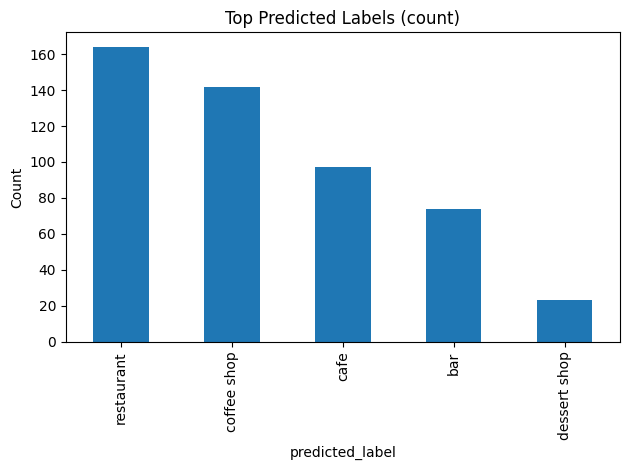

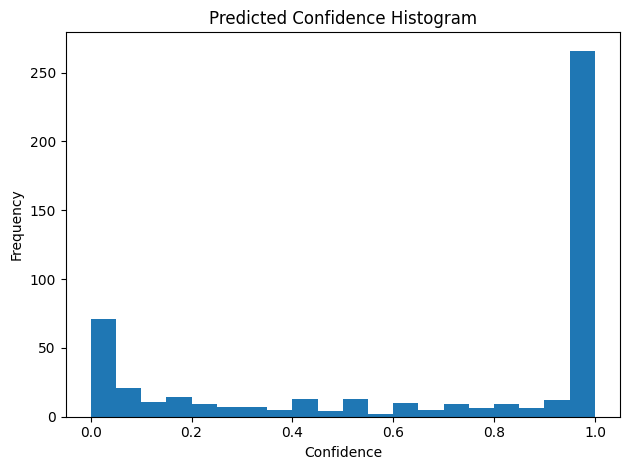

Saved: Task2_Outputs/plot_predicted_label_counts.png
Saved: Task2_Outputs/plot_confidence_hist.png
Saved: Task2_Outputs/table_mean_conf_by_label.csv


,predicted_label,count,mean
0,restaurant,164,0.644355
1,coffee shop,142,0.963007
2,cafe,97,0.666257
3,bar,74,0.232032
4,dessert shop,23,0.631305


In [22]:
# Visualise from existing zero-shot CSV (no re-scoring)
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate Outputs folder (Kaggle or local)
OUT_DIR = Path("./Task2_Outputs") if Path("./Task2_Outputs").exists() else Path("/kaggle/working/Task2_Outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Pick the source CSV (canonical -> alias -> latest timestamp)
canon = OUT_DIR / "zero_shot_per_venue_scores.csv"
alias = OUT_DIR / "zero-shot.csv"
candidates = sorted(OUT_DIR.glob("zero_shot_per_venue_scores_*.csv"))
src = canon if canon.exists() else (alias if alias.exists() else (candidates[-1] if candidates else None))
assert src is not None and src.exists(), f"No zero-shot CSV found in {OUT_DIR}"

print("Using source:", src)
df_out = pd.read_csv(src)

# ---Standardise/guarantee columns for visuals ---
# 1) If you have prob_* columns but no predicted_* yet, compute them
prob_cols = [c for c in df_out.columns if c.startswith("prob_")]
if prob_cols and ("predicted_label" not in df_out.columns or "predicted_conf" not in df_out.columns):
    def _clean(c): return c[5:].replace("_", " ") if c.startswith("prob_") else c
    idxmax = df_out[prob_cols].idxmax(axis=1)
    df_out["predicted_label"] = idxmax.map(_clean)
    df_out["predicted_conf"]  = df_out[prob_cols].max(axis=1)

# 2) If newer files have pred_label/pred_conf only, mirror them so the rest of this cell works unchanged
if "pred_label" in df_out.columns and "predicted_label" not in df_out.columns:
    df_out["predicted_label"] = df_out["pred_label"]
    df_out["predicted_conf"]  = df_out["pred_conf"]

# Determine score columns
# If you have a known label list, set it here. Otherwise infer numeric [0,1] columns.
KNOWN_LABELS = [
    "brunch","cafe","coffee specialty","vegan","seafood",
    "fine dining","casual dining","family friendly","dessert","bar","outdoor seating"
]
score_cols = [c for c in KNOWN_LABELS if c in df_out.columns]
if not score_cols:
    exclude = {"predicted_label","predicted_conf","lat","lon","osm_id"}
    numeric = df_out.select_dtypes(include=[np.number]).columns
    def looks_prob(col):
        s = df_out[col].dropna()
        return len(s) > 0 and (s.ge(0).mean() > 0.95) and (s.le(1).mean() > 0.95)
    score_cols = [c for c in numeric if c not in exclude and looks_prob(c)]

assert score_cols, "No score columns detected. Update KNOWN_LABELS to match your CSV headers."

# Ensure predicted columns exist
if "predicted_label" not in df_out.columns:
    df_out["predicted_label"] = df_out[score_cols].idxmax(axis=1)
if "predicted_conf" not in df_out.columns:
    df_out["predicted_conf"] = df_out[score_cols].max(axis=1)

# Plot 1: label counts
counts = df_out["predicted_label"].value_counts().head(12)
plt.figure()
counts.plot(kind="bar")
plt.title("Top Predicted Labels (count)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(OUT_DIR / "plot_predicted_label_counts.png", dpi=150)
plt.show()

# Plot 2: confidence histogram
plt.figure()
df_out["predicted_conf"].plot(kind="hist", bins=20)
plt.title("Predicted Confidence Histogram")
plt.xlabel("Confidence")
plt.tight_layout()
plt.savefig(OUT_DIR / "plot_confidence_hist.png", dpi=150)
plt.show()

# Summary table
summary = (
    df_out.groupby("predicted_label")["predicted_conf"]
          .agg(["count","mean"])
          .sort_values("count", ascending=False)
          .reset_index()
)
summary.to_csv(OUT_DIR / "table_mean_conf_by_label.csv", index=False)

print("Saved:", OUT_DIR / "plot_predicted_label_counts.png")
print("Saved:", OUT_DIR / "plot_confidence_hist.png")
print("Saved:", OUT_DIR / "table_mean_conf_by_label.csv")
summary.head(12)


**Insight: Predicted Confidence Histogram**

The confidence values cluster at two extremes. Most venues receive very high confidence (0.95–1.0) because their OSM descriptions clearly match the candidate labels. Another smaller group sits at very low confidence (<0.05), usually due to incomplete or unclear text. Only a few results fall in the middle, showing that the model tends to be either very certain or very uncertain based on the amount of information available.

**Insight: Top Predicted Labels**

The model assigns most venues to restaurant and coffee shop, reflecting how common these tags are in OSM descriptions. Cafés and bars appear less frequently but still form clear groups. Dessert shop is the smallest category, indicating fewer venues with text strongly matching this label. Overall, the distribution mirrors Melbourne’s hospitality landscape and shows that the model follows the dominant wording patterns in the dataset.

**Insight: Top Predicted Labels**

The model assigns most venues to restaurant and coffee shop, reflecting how common these tags are in OSM descriptions. Cafés and bars appear less frequently but still form clear groups. Dessert shop is the smallest category, indicating fewer venues with text strongly matching this label. Overall, the distribution mirrors Melbourne’s hospitality landscape and shows that the model follows the dominant wording patterns in the dataset.

In [24]:
!rm -f Task2_Outputs.zip && zip -r -q Task2_Outputs.zip Task2_Outputs
from IPython.display import FileLink, display
display(FileLink("Task2_Outputs.zip"))


/kaggle/working/Task2_Outputs.zip